In [1]:
%pip install sentencepiece --cert /etc/ssl/certs/ca-certificates.crt


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
%pip install matplotlib

  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/b8/90/2b3fd67ee273163faeda6d514be70b5596eaa0fd77b60ffc294ad0b34f5f/matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.8 MB/s eta 0:00:00a 0:00:01
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/78/f9/b6831508960d559581c448532ba4df312217072975486dbf2b24fcc5b76f/contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for cycler>=0.10 from https://files.pythonhosted.org/packages/e7/05/c19819d5e3d95294a6f5947fb9b9629efb316b96de511b418c53d245aae6/cycler-0.12.1-py3-none-any.whl.metadata
  Obtaining dependency information for fonttools>=4.28.2 from https://files.pythonhosted.org/packages/a6/6e/babde908b879a3b51ffc230919d06a804912559dd4cf8c94f3fa2af69fec/fonttools-4.66.1-cp312-cp312-manylinu

In [1]:
import os
import random
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
from math import floor
import sentencepiece as spm
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
# make sure GPU is used
if not torch.cuda.is_available():
    raise RuntimeError("no GPU available")

device = torch.device('cuda:0')


In [3]:
corpus = {
    "train" : {
        "en": "/srv/data/lt2326-h26/a1/train/en.txt", 
        "tr": "/srv/data/lt2326-h26/a1/train/tr.txt",
        "zh": "/srv/data/lt2326-h26/a1/train/zh.txt"
    },
    "valid" : {
        "en": "/srv/data/lt2326-h26/a1/valid/en.txt", 
        "tr": "/srv/data/lt2326-h26/a1/valid/tr.txt",
        "zh": "/srv/data/lt2326-h26/a1/valid/zh.txt"
    },
    "test" : {
        "en": "/srv/data/lt2326-h26/a1/test/en.txt", 
        "tr": "/srv/data/lt2326-h26/a1/test/tr.txt",
        "zh": "/srv/data/lt2326-h26/a1/test/zh.txt"
    } 
}

if not os.path.exists("tokenizers"):
    os.makedirs("tokenizers")

if not os.path.exists("results"):
    os.makedirs("results")

tok_prefix = {
    "char_level": "tokenizers/char_level_tok",
    "bpe_small": "tokenizers/bpe_small_tok",
    "bpe_large": "tokenizers/bpe_large_tok"
}

In [4]:
# todo: delete cell
with open("/srv/data/lt2326-h26/a1/train/en.txt") as f:
    en_contents = f.readlines()

with open("/srv/data/lt2326-h26/a1/train/tr.txt") as f:
    tr_contents = f.read()

with open("/srv/data/lt2326-h26/a1/train/zh.txt") as f:
    zh_contents = f.read()

In [5]:
# todo: delete cell
print(en_contents[:5])

['Since Jack Kirby had more than enough assignments, Lee assigned John Buscema the task of illustrating the new book."\n', 'Inuit means more than one, one person is an "Inuk".\n', 'Sunday edition until his death in 2017.\n', 'AIDS cases in most countries in Western Europe have fallen to levels not seen since the initial outbreak; many people attribute this trend to active education campaigns, blood transfusion screening and increased condom use.\n', 'His career has lasted over more than six decades.\n']


In [6]:
# find out how many unique characters there are,
# so that I know how big to set the vocab size to in the trainer
unique_chars = set()
for curr_f in corpus["train"].values():
    with open(curr_f, encoding="utf-8") as f:
        # read whole text in as a string, then add it to a set to get unique chars
        cont = f.read().strip()
    unique_chars.update(cont)

# add 4 to vocab size to account for bos, eos, unk, pad
train_vocab_size = len(unique_chars) + 4
print(train_vocab_size)
# note: realized that the number of unique chars that I found (9447) is significantly different than what the trainer below found (Alphabet size=6393)
# That is when I discovered that the sentencepiece trainer has a default coverage parameter that is not set to 100%.
# After updating the coverage to 1.0, the new value is "Alphabet size=9328". Still don't know where the missing 119 tokens are ...

9447


In [7]:
## train the character level tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()), # train on all languages in the training split
    model_prefix=tok_prefix['char_level'],
    model_type='char',
    vocab_size=train_vocab_size,
    character_coverage=1.0 # keep all tokens until the vocab size is reached
)

I0000 00:00:1791717227.140390 2352743 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/char_level_tok
  model_type: CHAR
  vocab_size: 9447
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  e

True

In [8]:
## train the BPE small vocab tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()), 
    model_prefix=tok_prefix["bpe_small"],
    model_type='bpe',
    vocab_size=10000, # todo: justify why 10,000 (has to be bigger than 9331 according to the error)
    character_coverage=1.0 # keep all tokens until the vocab size is reached - todo: should I still keep 1.0 coverage?
)

I0000 00:00:1791717228.014427 2352743 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/bpe_small_tok
  model_type: BPE
  vocab_size: 10000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eo

True

In [9]:
## train the BPE large vocab tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()),
    model_prefix=tok_prefix["bpe_large"],
    model_type='bpe',
    vocab_size=20000, # todo: justify why 20,000 (has to be bigger than 9331 according to the error)
    character_coverage=1.0 # keep all tokens until the vocab size is reached - todo: should I still keep 1.0 coverage?
)

I0000 00:00:1791717230.101351 2352743 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/bpe_large_tok
  model_type: BPE
  vocab_size: 20000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eo

True

In [10]:
######################
## Analyze tokenizers 
######################

# loop through tokenizer models
for i in tok_prefix.keys():
    # load the current pre-trained model
    curr_model = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    print("=========")
    print(f"MODEL: {i}")
    # get the vocab size for the current model
    print(f"vocabulary size: {curr_model.get_piece_size()}")
    print()
    
    # loop through each language split for the current model
    for lang, file in corpus["valid"].items():
        print(f"processing {lang}...")
        
        # read all the lines in the current language split,
        # to count the total number of tokens (using id) needed to encode the set
        with open(file, encoding="utf-8") as f:
            contents = f.read()
        total_num_unicode_chars = len(contents)
        encoded = curr_model.encode(contents, out_type=int)
        print(f"number of tokens needed to encode the set: {len(encoded):,}")

        # split the text on the newline character to get the sentences
        sents = contents.split("\n") # one line is one sentence
        num_sents = len(sents)

        # loop through each of the sentences in the language split
        # to calculate sentence-level metrics
        total_sent_length = 0
        for sent in sents:
            sent_encoded = curr_model.encode(sent, out_type=int)
            total_sent_length += len(sent_encoded)
    
        avg_sent_length = total_sent_length/num_sents
        print(f"average number of tokens per sentence: {avg_sent_length:.3f}")

        # number of chars in the whole text / number of tokens in the whole text
        avg_unicode_per_token = len(contents)/len(encoded) 
        print(f"average number of Unicode characters per token: {avg_unicode_per_token:.3f}")
        print()



MODEL: char_level
vocabulary size: 9331

processing en...
number of tokens needed to encode the set: 372,783
average number of tokens per sentence: 82.093
average number of Unicode characters per token: 1.000

processing tr...
number of tokens needed to encode the set: 372,114
average number of tokens per sentence: 99.602
average number of Unicode characters per token: 1.000

processing zh...
number of tokens needed to encode the set: 377,941
average number of tokens per sentence: 39.554
average number of Unicode characters per token: 1.000

MODEL: bpe_small
vocabulary size: 10000

processing en...
number of tokens needed to encode the set: 167,989
average number of tokens per sentence: 36.994
average number of Unicode characters per token: 2.219

processing tr...
number of tokens needed to encode the set: 172,981
average number of tokens per sentence: 46.301
average number of Unicode characters per token: 2.151

processing zh...
number of tokens needed to encode the set: 344,897
avera

In [11]:
## Examining sentences from the tokenizers

# loop through tokenizer models
for i in tok_prefix.keys():
    # load the current pre-trained model
    curr_model = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    print("=========")
    print(f"MODEL: {i}")
    print()
    
    # loop through each language split for the current model
    for lang, file in corpus["valid"].items():
        print(f"processing {lang}...")
        with open(file, encoding="utf-8") as f:
            lines = f.readlines()
            
        # save the first 2 sentences 
        for i in range(0,2):
            pieces = curr_model.encode(lines[i], out_type=str)
            print(pieces)
        print()
        

MODEL: char_level

processing en...
['▁', 'S', 'h', 'e', '▁', 'p', 'l', 'a', 'y', 'e', 'd', '▁', 'i', 'n', '▁', 't', 'w', 'o', '▁', 'm', 'a', 't', 'c', 'h', 'e', 's', '▁', 'a', 't', '▁', 't', 'h', 'i', 's', '▁', 'c', 'h', 'a', 'm', 'p', 'i', 'o', 'n', 's', 'h', 'i', 'p', '.']
['▁', 'A', 'f', 't', 'e', 'r', '▁', 't', 'h', 'e', 's', 'e', '▁', 'v', 'i', 'c', 't', 'o', 'r', 'i', 'e', 's', ',', '▁', 'h', 'e', '▁', 'w', 'a', 's', '▁', 'a', 'p', 'p', 'o', 'i', 'n', 't', 'e', 'd', '▁', 'a', 's', '▁', 't', 'h', 'e', '▁', 'o', 'r', 'g', 'a', 'n', 'i', 'z', 'i', 'n', 'g', '▁', 's', 'e', 'c', 'r', 'e', 't', 'a', 'r', 'y', '▁', 'o', 'f', '▁', 'D', 'M', 'K', '▁', 'i', 'n', '▁', 's', 'o', 'u', 't', 'h', 'e', 'r', 'n', '▁', 'T', 'a', 'm', 'i', 'l', '▁', 'N', 'a', 'd', 'u', '▁', 'd', 'i', 's', 't', 'r', 'i', 'c', 't', 's', '.']

processing tr...
['▁', 'G', 'e', 'r', 'm', 'a', 'n', 't', 'o', 'w', 'n', '▁', 'a', 'k', 'a', 'd', 'e', 'm', 'i', 's', 'i', 'n', 'e', '▁', 'd', 'e', 'v', 'a', 'm', '▁', 'e', 't'

In [12]:
###################################
### Part 2: the language models
###################################

train_config = {
    "num_layers": 2,
    "num_heads": 4,
    "hidden_dim": 256,
    "context_len": 128,
    "dropout": 0.1,
    "ff_dim": 1024,
    "batch_size": 64,
    "epochs": 20,
    "lr": 0.0003,
    "clip_norm": 2.4
}

def count_params(module):
    tot = 0
    for p in module.parameters():
        tot += p.numel()
    return tot

def create_causal_mask(seq_len: int, device):
    """
    Mask the upper right-hand triangle in the matrix (the future tokens)
    -inf = masked
    0 = unmasked

    :seq_len: len of context window
    return: masked tensor
    """
    # initialize matrix with all masked values
    start_matrix = torch.full((seq_len, seq_len), float("-inf"), device=device)
    # change triangle to 0's
    mask = torch.triu(start_matrix, diagonal=1)
    return mask
    
class MultiLangDataset(torch.utils.data.Dataset):
    """
    This class handles turning text from the corpus into PyTorch tensors and slices that the 
    batches can handle.
    """
    def __init__(self, sents, tokenizer, seq_len=128):
        self.seq_len = seq_len
        # turn the corpus text into one continuous list of tokenized ids
        # this will later be sliced into context windows of size seq_len
        all_ids = []
        for sent in tokenizer.encode(sents):
            # add bos and eos to each sentence encoding
            new_sent = [tokenizer.bos_id()] + sent + [tokenizer.eos_id()]
            all_ids.extend(new_sent)
        # turn id list into tensor
        self.encoded = torch.tensor(all_ids)

    def __len__(self):
        """
        return: number of context windows in the dataset
        """
        return (len(self.encoded) -1) // self.seq_len

    def __getitem__(self, idx):
        """
        :idx: index of interest
        return: feature and label vector at the given index
        """
        # multiply by context_window size to get to the right start idx in the "complete tensor"
        start_idx = idx * self.seq_len 
        # stop idx is 1 space after the end of context window 
        stop_idx = start_idx + self.seq_len + 1 
        window = self.encoded[start_idx:stop_idx]

        X = window[:-1]
        y = window[1:]
        return X,y

class DecoderLayer(nn.Module):
    """
    This is the class managing the decoder layer of the Transformer.
    It uses :
    - Multi-head attention for the masked self-attention mechanism
    - SwiGLU activation function for feed-forward network
    - RMSNorm for normalization at the input of attention and feed-forward network 
    """
    def __init__(self, hidden_dim, num_heads, ff_dim, dropout=0.1):
        """
        :hidden_dim: dimension of hidden vector
        :num_heads: number of attention heads
        :ff_dim: feed-forward dimension
        :dropout: dropout probability
        """
        super().__init__()
        self.self_attn = MultiHeadAttn(hidden_dim, num_heads, dropout)
        self.ffn = SwiGLU(hidden_dim, ff_dim)
        # set up two normalizations (before attention block and before feed-forward)
        self.norm1 = nn.RMSNorm(hidden_dim)  # RMSNorm as used in Jurafsky
        self.norm2 = nn.RMSNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, X, mask=None):
        # self attention
        out = self.norm1(X)
        out = self.self_attn(out, out, out, mask)
        X = X + self.dropout(out)

        # feed-forward
        out = self.norm2(X)
        out = self.ffn(out)

        return X + self.dropout(out)

class TransformerModel(nn.Module):
    """
    Decoder-only Transformer language model.
    
    """
    def __init__(self, num_layers, num_heads, hidden_dim, seq_len, vocab_size, ff_dim, device, dropout=0.1):
        """
        :num_layers: number of decoder layers
        :num_heads: number of attention heads
        :hidden_dim: dimension of hidden vector
        :seq_len: context window length
        :vocab_size: number of tokens in vocabulary
        :ff_dim: feed-forward network dimension
        :device: device that model runs on (gpu)
        :dropout: dropout probability (consistent throughout model)
        """
        super().__init__()
        # lookup table for token vector in vocab
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        # lookup table for vector per position in context window
        self.position_embedding = nn.Embedding(seq_len, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.decoders = nn.ModuleList()
        self.seq_len = seq_len
        
        # loop to create the number of decoder layers in config
        for _ in range(num_layers):
            self.decoders.append(DecoderLayer(hidden_dim, num_heads, ff_dim, dropout))
            
        self.norm = nn.RMSNorm(hidden_dim)
        # output logits (score) for each token in the vocab
        self.out = nn.Linear(hidden_dim, vocab_size)

        self.device = device

    def forward(self, ids, mask=None):
        """
        :ids: tensor of token ids (shape: batch_size, len)
        :mask: causal mask 

        return: score for every possible next token (shape: batch_size, seq_len, vocab_size)
        """
        # calculate position embedding
        # (use the actual ids tensor len as stop value instead of seq_len
        # because last window might be shorter than seq_len) 
        positions = torch.arange(ids.shape[1], device=self.device)

        # each token's vector is the token embedding + position embedding
        X = self.embedding(ids) + self.position_embedding(positions)
        X = self.dropout(X)
        
        for decoder in self.decoders:
            X = decoder(X, mask)
            
        X = self.norm(X)
        
        return self.out(X)


class SwiGLU(nn.Module):
    """
    SwiGLU activation function for feed-forward network.
    
    """
    def __init__(self, hidden_dim, interm_dim):
        """
        :hidden_dim: size of hidden vector
        :interm_dim: size of bigger intermediate vectors
        """
        super().__init__()
        self.gate = nn.Linear(hidden_dim, interm_dim)
        self.up = nn.Linear(hidden_dim, interm_dim)
        self.down = nn.Linear(interm_dim, hidden_dim)
        self.activation = nn.SiLU()
    
    def forward(self, X):
        # pass gate vector through activation function
        new_gate_vec = self.activation(self.gate(X))
        X =  new_gate_vec * self.up(X)
        # shrink back
        X = self.down(X)
        
        return X


class MultiHeadAttn(nn.Module):
    """
    Masked multi-head self-attention.
    """
    def __init__(self, hidden_dim, num_heads, dropout):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = floor(hidden_dim/num_heads)
        self.dropout = dropout
        
        self.q_proj = nn.Linear(hidden_dim, hidden_dim)
        self.k_proj = nn.Linear(hidden_dim, hidden_dim)
        self.v_proj = nn.Linear(hidden_dim, hidden_dim)
        self.out_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, q, k, v, mask=None):
        batch_size, seq_len, hidden_dim = q.shape

        #project
        queries = self.q_proj(q).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1,2)
        keys = self.k_proj(k).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1,2)
        values = self.v_proj(v).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1,2)

        # use dropout in dot product only if training
        if self.training:
            dropout_prob = self.dropout
        else:
            dropout_prob = 0.0

        out = F.scaled_dot_product_attention(queries,
                                               keys,
                                               values,
                                               attn_mask=mask,
                                               dropout_p=dropout_prob
                                               )
        # merge info from the heads
        out = out.transpose(1,2).reshape(batch_size, seq_len, hidden_dim)
        out = self.out_proj(out)
        
        return out



In [14]:
# Training block

# create dataset
# merge all languages from the training split - save as a list of sentences
train_text = []
for file in list(corpus["train"].values()):
    with open(file, encoding="utf-8") as f:
        curr_contents = f.readlines()
    train_text.extend(curr_contents)

# do the same for validation set
valid_text = []
for file in list(corpus["valid"].values()):
    with open(file, encoding="utf-8") as f:
        curr_contents = f.readlines()
    valid_text.extend(curr_contents)

# save training and validation loss to plot later
history = {}

# loop through tokenizer models
for i in tok_prefix.keys():
    print(f"Training model: {i}")
    # create the dataset using the current tokenizer
    tokenizer = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    # train - load data
    dataset = MultiLangDataset(train_text, tokenizer, train_config["context_len"])
    my_generator = torch.Generator().manual_seed(42)
    dataloader = DataLoader(dataset,
                            train_config["batch_size"],
                            shuffle=True,
                            generator=my_generator # make sure that it always uses same seed for shuffle
                           )
    # validation - load data
    valid_dataset = MultiLangDataset(valid_text, tokenizer, train_config["context_len"])
    valid_dataloader = DataLoader(valid_dataset,
                            train_config["batch_size"],
                            shuffle=False # do not shuffle
                           )

    # create model
    model = TransformerModel(
        num_layers=train_config["num_layers"],
        num_heads=train_config["num_heads"],
        hidden_dim=train_config["hidden_dim"],
        ff_dim=train_config["ff_dim"],
        seq_len=train_config["context_len"],
        vocab_size=tokenizer.get_piece_size(),
        device=device,
        dropout=train_config["dropout"]
    ).to(device)

    # print model parameters
    in_embedding_param_count = count_params(model.embedding)
    out_embedding_param_count = count_params(model.out)
    print(f"total model parameters: {count_params(model):,}")
    print(f"input embeddings parameter count: {in_embedding_param_count:,}")
    print(f"output layer parameter count: {out_embedding_param_count:,}\n")

    optimizer = optim.AdamW(model.parameters(), lr=train_config["lr"])
    loss_fn = nn.CrossEntropyLoss()

    best_loss = float("inf")
    history[i] = {
        "train_loss": [], 
        "valid_loss": []
    }

    # training loop
    for epoch in range(train_config["epochs"]):
        model.train()
        epoch_loss = 0

        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)

            # causal mask
            mask = create_causal_mask(X.shape[1], device)

            # forward
            optimizer.zero_grad()
            outputs = model(X, mask.unsqueeze(0))
            loss = loss_fn(outputs.view(-1, outputs.shape[-1]), y.view(-1))
            
            # backward
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),
                                           train_config["clip_norm"],
                                           error_if_nonfinite=True
                                          )

            optimizer.step()
            epoch_loss += loss.item()
                
        # evaluate on validation data
        avg_loss = epoch_loss / len(dataloader)
        model.eval()
        total_loss = 0.0
        total_tokens = 0
        with torch.no_grad():
            for X, y in valid_dataloader:
                X, y = X.to(device), y.to(device)
                mask = create_causal_mask(X.shape[1], device)
                outputs = model(X, mask.unsqueeze(0))
                loss = loss_fn(outputs.view(-1, outputs.shape[-1]), y.view(-1))
                total_loss += loss.item() * y.numel()
                total_tokens += y.numel()

        valid_loss = total_loss / total_tokens
        print(f"Epoch {epoch+1}/{train_config['epochs']}, train loss: {avg_loss:.3f}, valid loss: {valid_loss:.3f}")
        
        # save loss to history
        history[i]["train_loss"].append(avg_loss)
        history[i]["valid_loss"].append(valid_loss)
        
        if valid_loss < best_loss:
            best_loss = valid_loss
            torch.save(model.state_dict(), f"results/{i}_model_epochs{train_config["epochs"]}_batchsize{train_config["batch_size"]}.pth")

    print("========================\n")
    

Training model: char_level
total model parameters: 6,924,659
input embeddings parameter count: 2,388,736
output layer parameter count: 2,398,067

Epoch 1/20, train loss: 3.711, valid loss: 3.191
Epoch 2/20, train loss: 3.076, valid loss: 2.879
Epoch 3/20, train loss: 2.869, valid loss: 2.736
Epoch 4/20, train loss: 2.758, valid loss: 2.653
Epoch 5/20, train loss: 2.686, valid loss: 2.602
Epoch 6/20, train loss: 2.633, valid loss: 2.563
Epoch 7/20, train loss: 2.594, valid loss: 2.536
Epoch 8/20, train loss: 2.561, valid loss: 2.514
Epoch 9/20, train loss: 2.534, valid loss: 2.493
Epoch 10/20, train loss: 2.511, valid loss: 2.480
Epoch 11/20, train loss: 2.491, valid loss: 2.468
Epoch 12/20, train loss: 2.473, valid loss: 2.456
Epoch 13/20, train loss: 2.458, valid loss: 2.444
Epoch 14/20, train loss: 2.443, valid loss: 2.437
Epoch 15/20, train loss: 2.431, valid loss: 2.428
Epoch 16/20, train loss: 2.419, valid loss: 2.423
Epoch 17/20, train loss: 2.408, valid loss: 2.416
Epoch 18/20, 

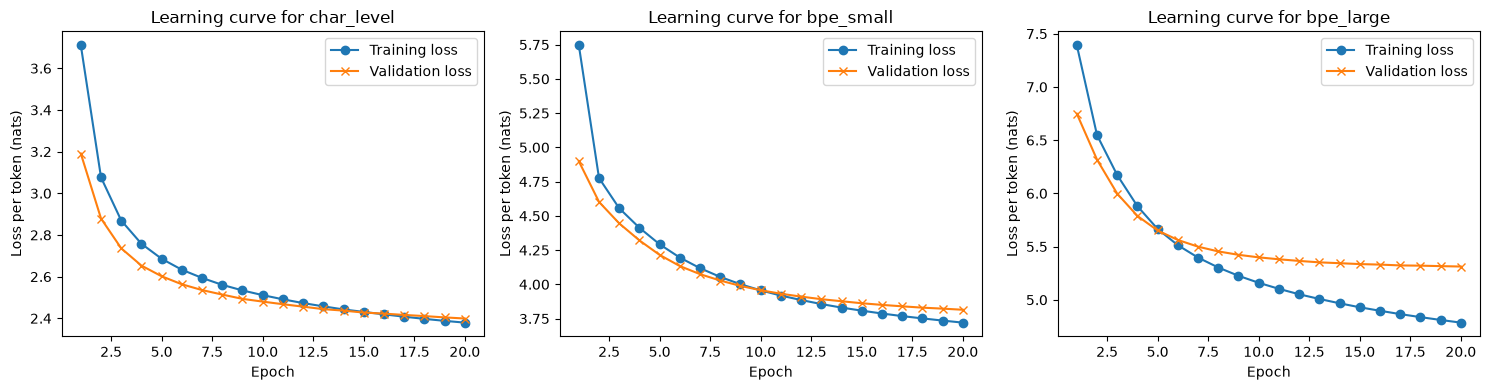

In [16]:
# plot learning curves

fig, ax = plt.subplots(nrows=1, ncols=len(history), figsize=(5*len(history), 4),
                       sharey=False, squeeze=False
                      )
ax = ax[0]
for ax_idx, (name, h) in enumerate(history.items()):
    epochs = range(1, len(h["valid_loss"]) + 1)
    ax[ax_idx].plot(epochs, h["train_loss"], marker="o", label="Training loss")
    ax[ax_idx].plot(epochs, h["valid_loss"], marker="x", label="Validation loss")

    ax[ax_idx].set_title(f"Learning curve for {name}")
    ax[ax_idx].set_xlabel("Epoch")
    ax[ax_idx].set_ylabel("Loss per token (nats)")
    ax[ax_idx].legend()

fig.tight_layout()
fig.savefig(f"results/learning_curves_epochs{train_config["epochs"]}_batchsize{train_config["batch_size"]}.png", dpi=200)
plt.show()
